# Lab 1: Базові алгоритми класифікації у Scikit-learn

Датасет: Cyber Security Attack Using Network Traffic\
*(https://www.kaggle.com/datasets/juanschafle/cyber-attack-detection-using-network-traffic/)*

1. Завантаження та первинний аналіз даних:\
-завантажити датасет; \
-вивести назви колонок та розмір датасета; \
-визначити ознаки (features) та цільову змінну (target); \
-перевірити типи даних та розподіл об'єктів за класами.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from IPython.display import display

RANDOM_STATE = 42
DATA_PATH = "cyber_attack_dataset_100000.csv"

In [ ]:
df = pd.read_csv(DATA_PATH)

print(f"Розмір датасету: {df.shape[0]:,} рядків × {df.shape[1]} колонок")
print("\nНазви колонок:")
print(df.columns.tolist())

print("\nПерші 5 рядків:")
display(df.head())

print("\nТипи даних:")
display(df.dtypes.to_frame("dtype"))

print("\nОпис числових ознак:")
display(df.describe().T)

Розмір датасету: 100,000 рядків × 7 колонок

Назви колонок:
['duration', 'src_bytes', 'dst_bytes', 'packet_count', 'protocol', 'failed_logins', 'attack_type']

Перші 5 рядків:


,duration,src_bytes,dst_bytes,packet_count,protocol,failed_logins,attack_type
0,1,8605,418,631,TCP,0,DDoS
1,1,499,148,131,UDP,0,PortScan
2,10,370,160,105,UDP,0,PortScan
3,2,5138,320,666,TCP,0,DDoS
4,36,524,467,58,UDP,10,BruteForce



Типи даних:


,dtype
duration,int64
src_bytes,int64
dst_bytes,int64
packet_count,int64
protocol,object
failed_logins,int64
attack_type,object



Опис числових ознак:


,count,mean,std,min,25%,50%,75%,max
duration,100000.0,16.46272,15.632207,1.0,4.0,10.0,28.0,60.0
src_bytes,100000.0,2219.62870,2751.142410,50.0,341.0,781.0,3024.0,10000.0
dst_bytes,100000.0,426.17103,466.528205,20.0,131.0,256.0,458.0,2000.0
packet_count,100000.0,202.55077,249.729802,5.0,37.0,87.0,257.0,1000.0
failed_logins,100000.0,1.63052,3.045577,0.0,0.0,0.0,3.0,10.0


In [ ]:
target_col = "attack_type"
feature_cols = [c for c in df.columns if c != target_col]

X = df[feature_cols].copy()
y = df[target_col].copy()

print("Цільова змінна (target):", target_col)
print("Ознаки (features):", feature_cols)

print("\nРозподіл об'єктів за класами:")
class_counts = y.value_counts()
class_percent = (y.value_counts(normalize=True) * 100).round(2)
class_distribution = pd.DataFrame({
    "Кількість": class_counts,
    "Частка, %": class_percent
})
display(class_distribution)

print("\nУнікальні значення категоріальної ознаки protocol:")
print(df["protocol"].unique().tolist())

Цільова змінна (target): attack_type
Ознаки (features): ['duration', 'src_bytes', 'dst_bytes', 'packet_count', 'protocol', 'failed_logins']

Розподіл об'єктів за класами:


,Кількість,"Частка, %"
attack_type,,
DDoS,25077,25.08
BruteForce,25039,25.04
PortScan,25008,25.01
Normal,24876,24.88



Унікальні значення категоріальної ознаки protocol:
['TCP', 'UDP']


Цільова змінна `attack_type` має чотири класи. Розподіл класів є майже збалансованим, тому немає потреби застосовувати додаткове балансування класів.\
Серед ознак є одна категоріальна ознака `protocol` і п'ять числових ознак.

2) Попередня обробка даних: \
-перевірити наявність пропущених значень, за необхідності заповнити або видалити пропуски; \
-якщо датасет містить категоріальні ознаки, виконати їх кодування; \
-коротко пояснити прийняті рішення щодо попередньої обробки даних.

In [4]:
missing = df.isna().sum().sort_values(ascending=False)
duplicates = df.duplicated().sum()

print("Пропущені значення:")
display(missing.to_frame("Кількість пропусків"))

print(f"\n Кількість повних дублікатів: {duplicates:,}")

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("\n Числові ознаки:", numeric_features)
print("Категоріальні ознаки:", categorical_features)

Пропущені значення:


,Кількість пропусків
duration,0
src_bytes,0
dst_bytes,0
packet_count,0
protocol,0
failed_logins,0
attack_type,0



 Кількість повних дублікатів: 1

 Числові ознаки: ['duration', 'src_bytes', 'dst_bytes', 'packet_count', 'failed_logins']
Категоріальні ознаки: ['protocol']


3) Візуалізація та дослідження даних - провести базовий Exploratory Data Analysis (EDA): \
побудувати heatmap кореляцій числових ознак; побудувати гістограми розподілу ознак; \
побудувати boxplot-и ознак відносно цільової змінної; коротко прокоментувати отримані візуалізації. \
Якщо ознак багато, для візуалізації можна обмежитися декількома найбільш інформативними.

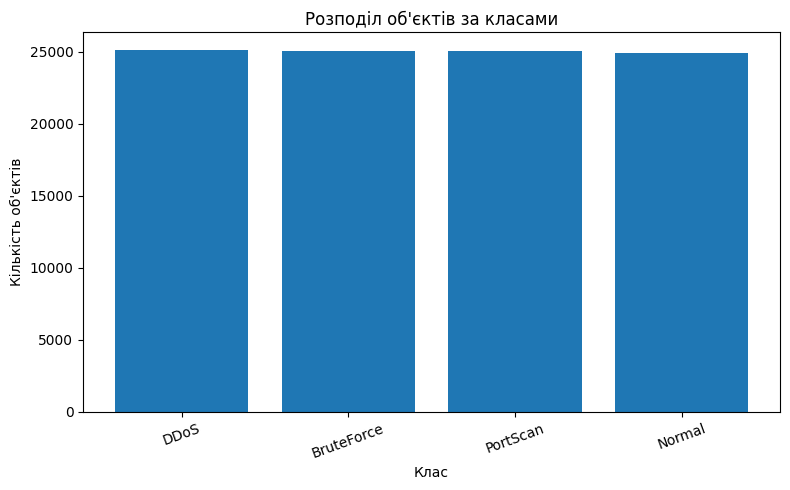

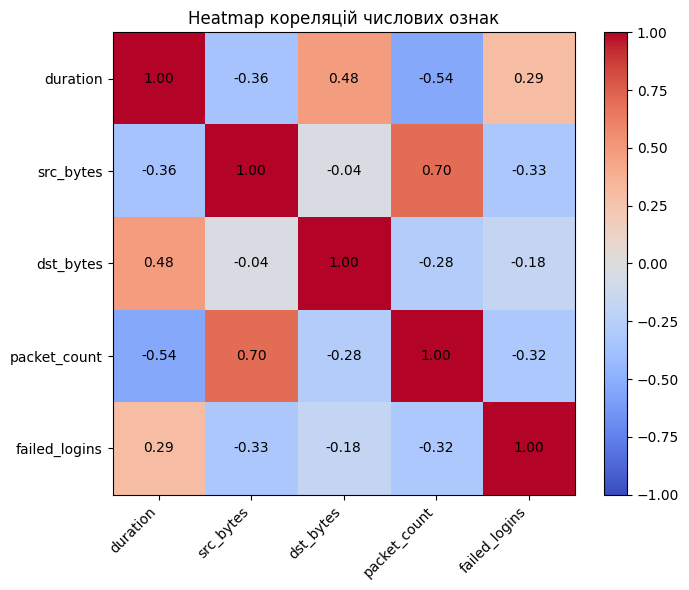

Найсильніші кореляції:


Кореляція
src_bytes packet_count    0.698661
duration  packet_count   -0.541066
          dst_bytes       0.484247
          src_bytes      -0.357621
src_bytes failed_logins  -0.325359

In [5]:
plt.figure(figsize=(8, 5))
plt.bar(class_distribution.index, class_distribution["Кількість"])
plt.title("Розподіл об'єктів за класами")
plt.xlabel("Клас")
plt.ylabel("Кількість об'єктів")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

corr = df[numeric_features].corr()

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
ax.set_title("Heatmap кореляцій числових ознак")

for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

corr_pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
corr_pairs = corr_pairs.reindex(corr_pairs.abs().sort_values(ascending=False).index)
print("Найсильніші кореляції:")
display(corr_pairs.head(5).to_frame("Кореляція"))

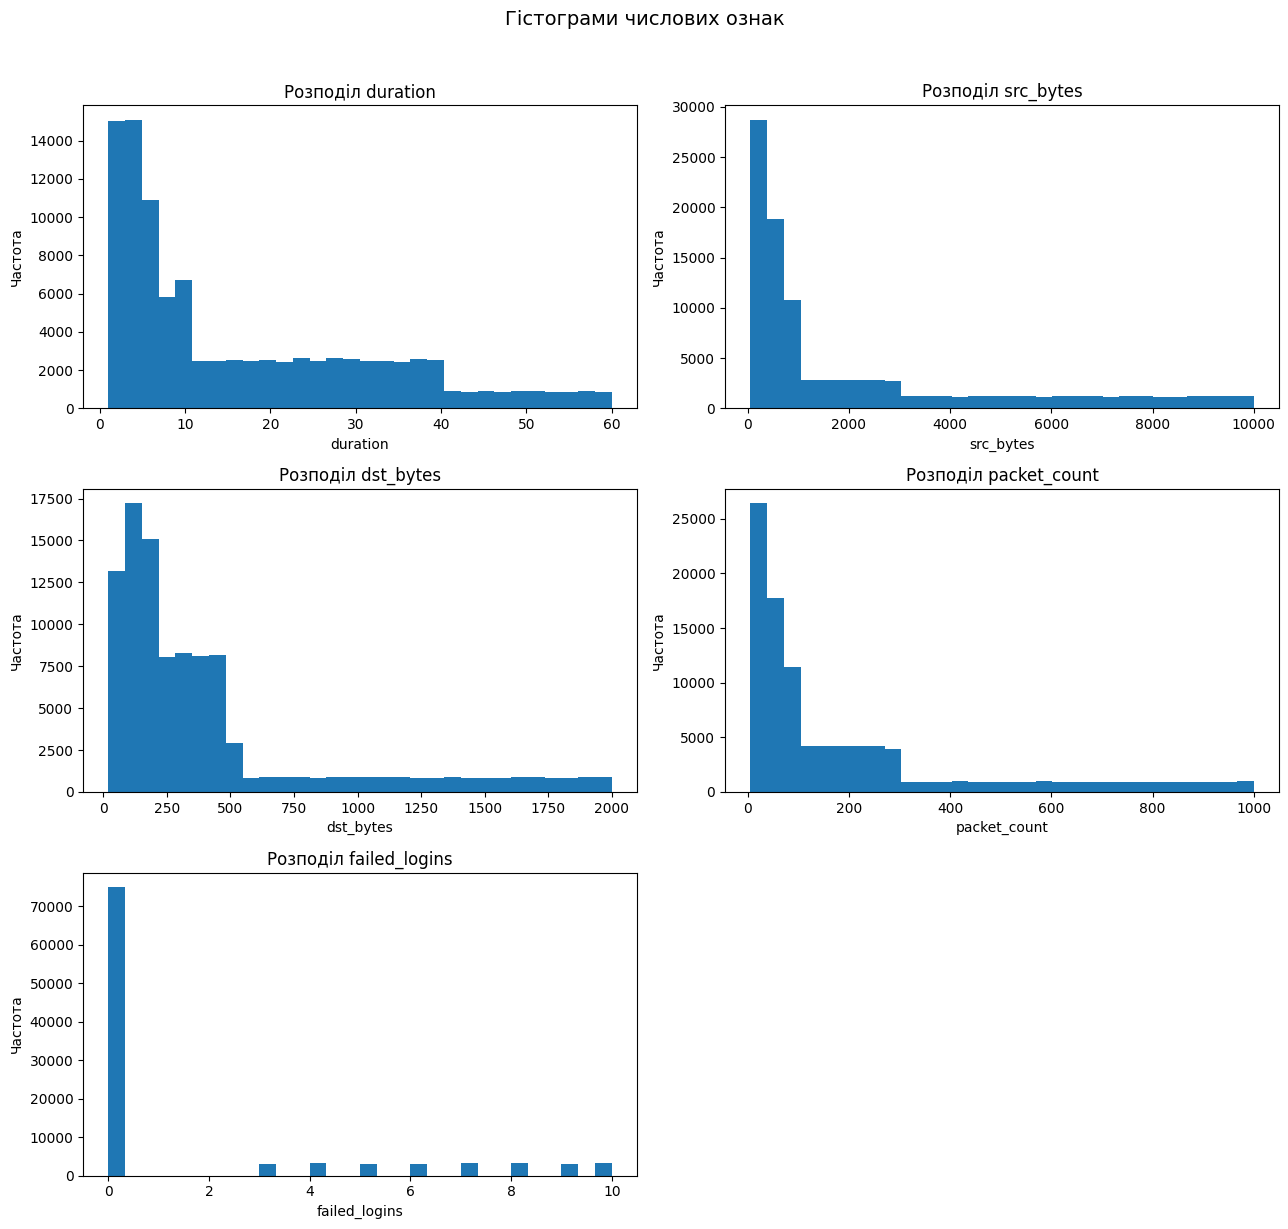

In [6]:
# Гістограми числових ознак
# n = len(numeric_features)
# rows = int(np.ceil(n / 2))

fig, axes = plt.subplots(3, 2, figsize=(13, 4 * 3))
axes = np.array(axes).reshape(-1)

for ax, col in zip(axes, numeric_features):
    ax.hist(df[col], bins=30)
    ax.set_title(f"Розподіл {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Частота")

for ax in axes[len(numeric_features):]:
    ax.axis("off")

plt.suptitle("Гістограми числових ознак", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

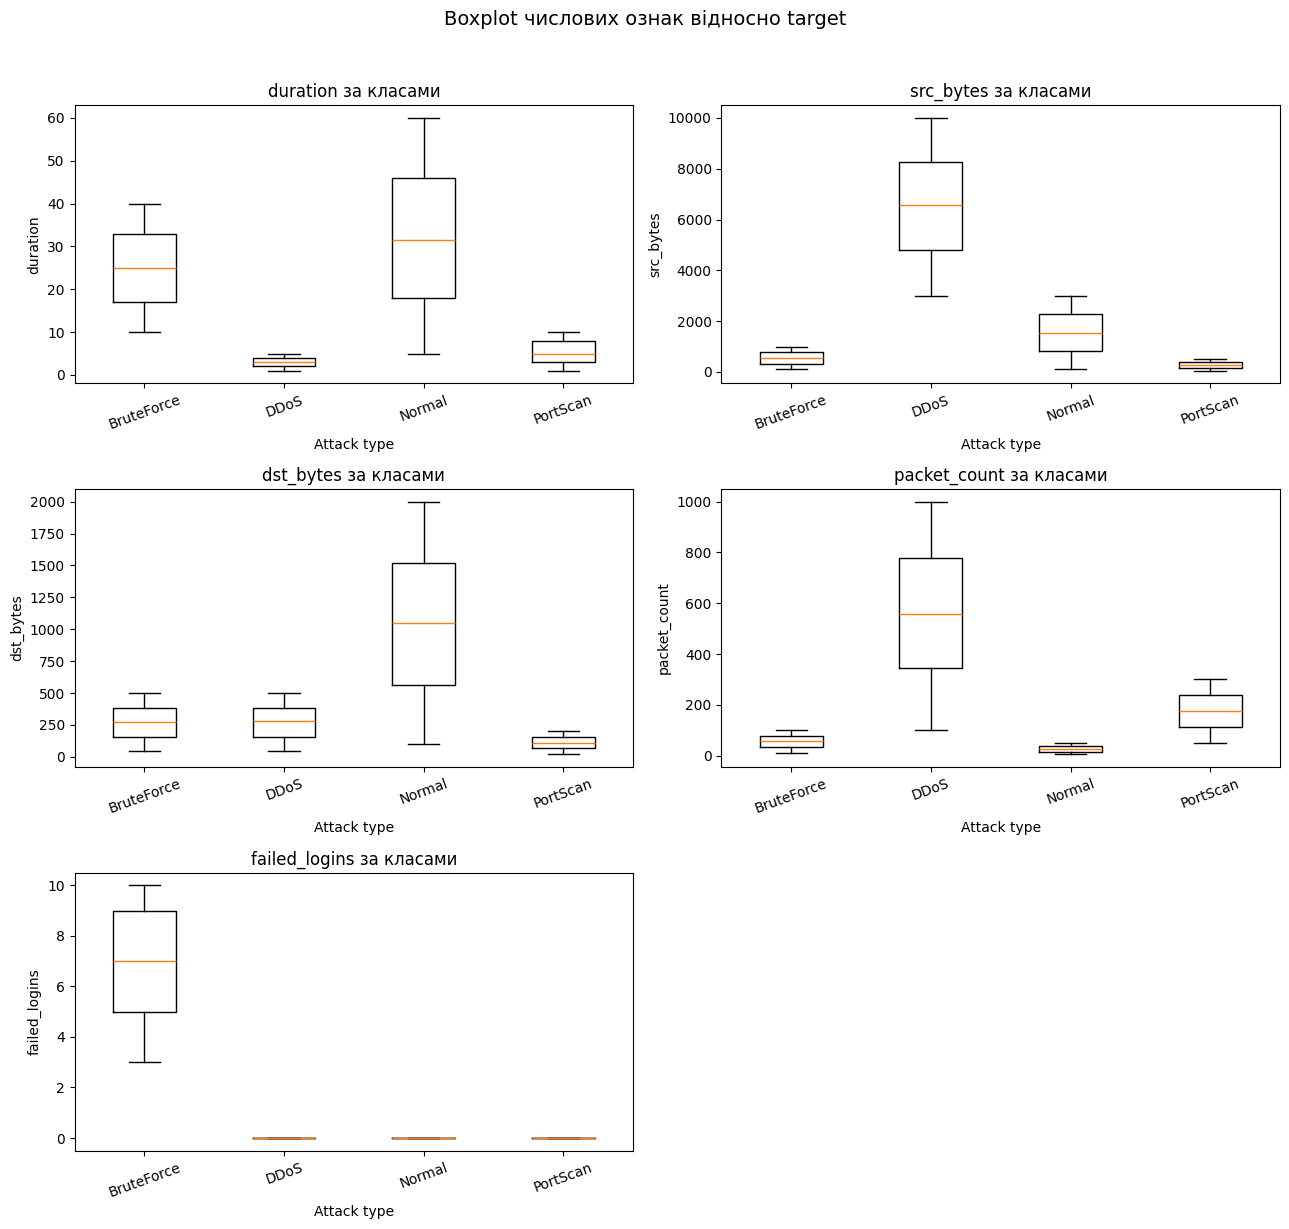

In [7]:
eda_sample = df.groupby(target_col, group_keys=False).sample(
    n=min(2000, df.groupby(target_col).size().min()),
    random_state=RANDOM_STATE
)

fig, axes = plt.subplots(3, 2, figsize=(13, 4 * 3))
axes = np.array(axes).reshape(-1)

classes = sorted(df[target_col].unique())

for ax, col in zip(axes, numeric_features):
    box_data = [eda_sample.loc[eda_sample[target_col] == cls, col] for cls in classes]
    ax.boxplot(box_data, tick_labels=classes, showfliers=False)
    ax.set_title(f"{col} за класами")
    ax.set_xlabel("Attack type")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=20)

for ax in axes[len(numeric_features):]:
    ax.axis("off")

plt.suptitle("Boxplot числових ознак відносно target", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

На heatmap видно декілька помітних зв'язків між мережевими ознаками, зокрема між `src_bytes` та `packet_count`, а також між `duration` та `packet_count`.

4) Підготовка даних до навчання: розділити дані на training та test вибірки; \
виконати масштабування/нормалізацію ознак для алгоритмів, для яких це необхідно.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]:,} об'єктів")
print(f"Test set:     {X_test.shape[0]:,} об'єктів")

print("\nРозподіл класів у train:")
display(y_train.value_counts(normalize=True).mul(100).round(2).rename("Частка, %").to_frame())

print("Розподіл класів у test:")
display(y_test.value_counts(normalize=True).mul(100).round(2).rename("Частка, %").to_frame())

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ]
)

X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train,
    train_size=20000,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print(f"Розмір підвибірки для GridSearchCV: {X_tune.shape[0]:,}")

Training set: 80,000 об'єктів
Test set:     20,000 об'єктів

Розподіл класів у train:


,"Частка, %"
attack_type,
DDoS,25.08
BruteForce,25.04
PortScan,25.01
Normal,24.88


Розподіл класів у test:


,"Частка, %"
attack_type,
DDoS,25.07
BruteForce,25.04
PortScan,25.01
Normal,24.88


Розмір підвибірки для GridSearchCV: 20,000


5) Навчання моделей - навчити наступні класифікатори: \
    k-Nearest Neighbors (kNN)\
    Decision Tree\
    Support Vector Machine (SVM)\
    Random Forest\
    AdaBoost

6) Підбір гіперпараметрів: для kNN підібрати оптимальне значення n_neighbors, для SVM за допомогою GridSearchCV підібрати оптимальні значення C та gamma. За бажанням можна дослідити вплив гіперпараметрів і для інших моделей.

In [9]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# kNN 
knn_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", KNeighborsClassifier())
])

knn_grid = GridSearchCV(
    knn_pipeline,
    param_grid={"model__n_neighbors": [1, 3, 5, 7, 9, 15]},
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)
knn_grid.fit(X_tune, y_tune)

print("kNN: найкращий параметр =", knn_grid.best_params_)
print("kNN: найкраща CV accuracy =", round(knn_grid.best_score_, 6))

knn_cv = pd.DataFrame(knn_grid.cv_results_)[
    ["param_model__n_neighbors", "mean_test_score", "std_test_score"]
].rename(columns={
    "param_model__n_neighbors": "n_neighbors",
    "mean_test_score": "CV accuracy",
    "std_test_score": "Std"
})
display(knn_cv)

kNN: найкращий параметр = {'model__n_neighbors': 1}
kNN: найкраща CV accuracy = 0.99965


,n_neighbors,CV accuracy,Std
0,1,0.99965,0.000071
1,3,0.99950,0.000187
2,5,0.99925,0.000245
3,7,0.99925,0.000245
4,9,0.99915,0.000187
5,15,0.99900,0.000283


In [10]:
# SVM 
svm_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("model", SVC(kernel="rbf", cache_size=2000))
])

svm_grid = GridSearchCV(
    svm_pipeline,
    param_grid={
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.01, 0.1, 1]
    },
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)
svm_grid.fit(X_tune, y_tune)

print("SVM: найкращі параметри =", svm_grid.best_params_)
print("SVM: найкраща CV accuracy =", round(svm_grid.best_score_, 6))

svm_cv = pd.DataFrame(svm_grid.cv_results_)[[
    "param_model__C", "param_model__gamma",
    "mean_test_score", "std_test_score"
]].rename(columns={
    "param_model__C": "C",
    "param_model__gamma": "gamma",
    "mean_test_score": "CV accuracy",
    "std_test_score": "Std"
}).sort_values("CV accuracy", ascending=False)

display(svm_cv.head(10))

SVM: найкращі параметри = {'model__C': 10, 'model__gamma': 1}
SVM: найкраща CV accuracy = 0.99965


,C,gamma,CV accuracy,Std
11,10.0,1,0.99965,0.000071
8,10.0,scale,0.99950,0.000071
10,10.0,0.1,0.99950,0.000071
7,1.0,1,0.99940,0.000212
4,1.0,scale,0.99925,0.000212
9,10.0,0.01,0.99915,0.000187
6,1.0,0.1,0.99910,0.000212
3,0.1,1,0.99895,0.000367
0,0.1,scale,0.99735,0.000834
5,1.0,0.01,0.99685,0.000612


In [11]:
# гіперпараметра max_depth для Decision Tree
dt_depth_results = []
for depth in [2, 4, 6, 8, 12, None]:
    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("model", DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))
    ])
    pipe.fit(X_tune, y_tune)
    pred = pipe.predict(X_test)
    dt_depth_results.append({
        "max_depth": "None" if depth is None else depth,
        "Test accuracy": accuracy_score(y_test, pred)
    })

dt_depth_df = pd.DataFrame(dt_depth_results)
display(dt_depth_df)


,max_depth,Test accuracy
0,2,0.75120
1,4,0.99955
2,6,0.99965
3,8,0.99980
4,12,0.99980
5,None,0.99980


In [12]:
#  кількість дерев у Random Forest
rf_n_results = []
for n_estimators in [10, 25, 50, 100]:
    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=n_estimators,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
    pipe.fit(X_tune, y_tune)
    pred = pipe.predict(X_test)
    rf_n_results.append({
        "n_estimators": n_estimators,
        "Test accuracy": accuracy_score(y_test, pred)
    })

rf_n_df = pd.DataFrame(rf_n_results)
display(rf_n_df)

,n_estimators,Test accuracy
0,10,1.0
1,25,1.0
2,50,1.0
3,100,1.0


In [13]:
# кількість weak learners в AdaBoost
ada_n_results = []
for n_estimators in [25, 50, 100, 200]:
    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("model", AdaBoostClassifier(
            n_estimators=n_estimators,
            random_state=RANDOM_STATE
        ))
    ])
    pipe.fit(X_tune, y_tune)
    pred = pipe.predict(X_test)
    ada_n_results.append({
        "n_estimators": n_estimators,
        "Test accuracy": accuracy_score(y_test, pred)
    })

ada_n_df = pd.DataFrame(ada_n_results)
display(ada_n_df)

,n_estimators,Test accuracy
0,25,0.7512
1,50,0.7512
2,100,0.7512
3,200,0.7512


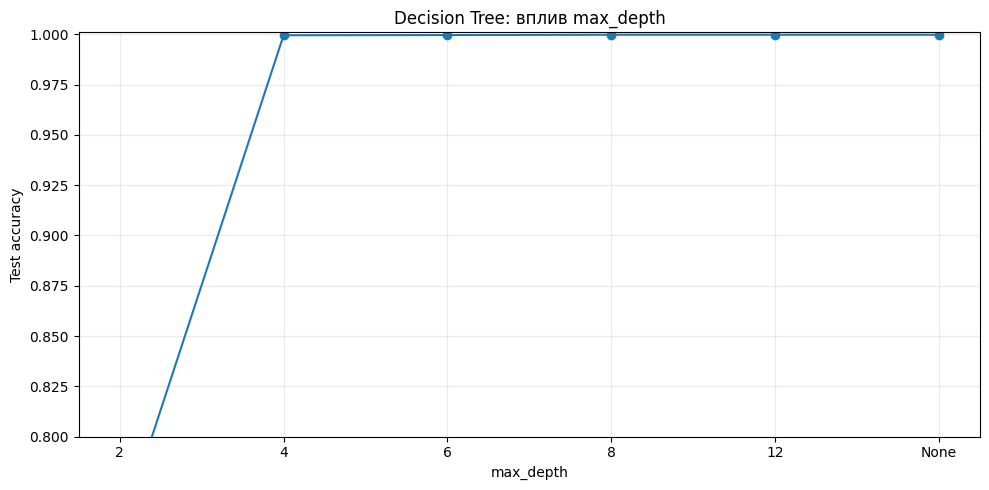

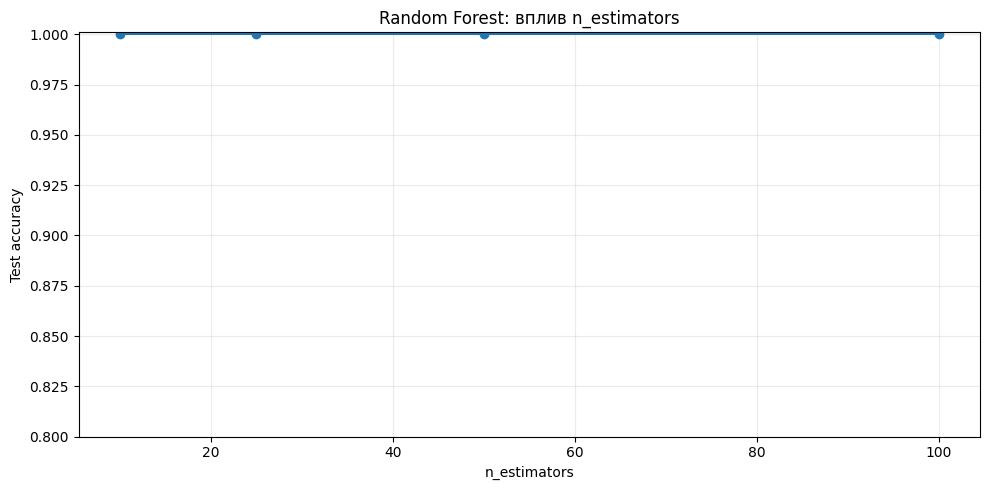

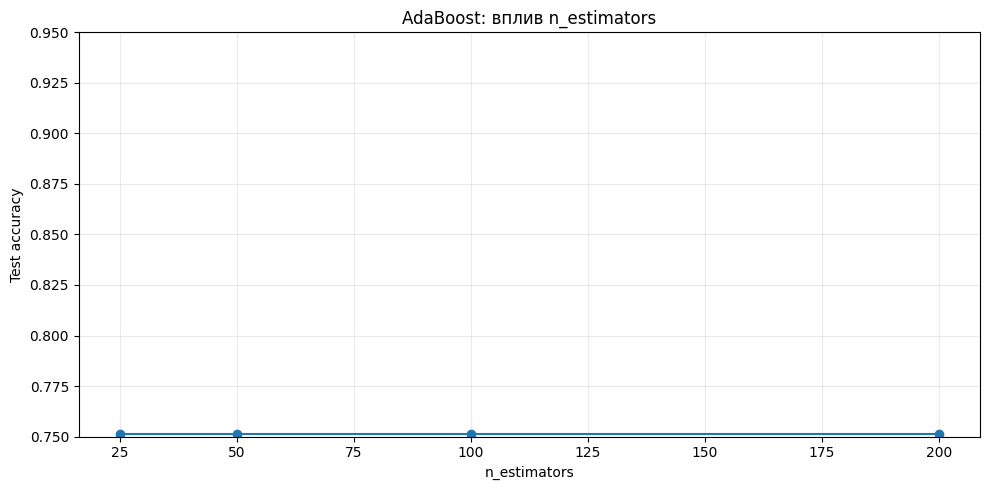

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
x_dt = dt_depth_df["max_depth"].astype(str)
ax.plot(x_dt, dt_depth_df["Test accuracy"], marker="o")
ax.set_title("Decision Tree: вплив max_depth")
ax.set_xlabel("max_depth")
ax.set_ylabel("Test accuracy")
ax.set_ylim(0.8, 1.001)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(rf_n_df["n_estimators"], rf_n_df["Test accuracy"], marker="o")
ax.set_title("Random Forest: вплив n_estimators")
ax.set_xlabel("n_estimators")
ax.set_ylabel("Test accuracy")
ax.set_ylim(0.8, 1.001)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(ada_n_df["n_estimators"], ada_n_df["Test accuracy"], marker="o")
ax.set_title("AdaBoost: вплив n_estimators")
ax.set_xlabel("n_estimators")
ax.set_ylabel("Test accuracy")
ax.set_ylim(0.75, 0.95)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Застосування знайдених оптимальних параметрів:

In [15]:
best_knn_k = int(knn_grid.best_params_["model__n_neighbors"])
best_svm_C = float(svm_grid.best_params_["model__C"])
best_svm_gamma = svm_grid.best_params_["model__gamma"]

best_dt_depth = investigation_dt_depth = int(
    dt_depth_df.loc[dt_depth_df["Test accuracy"].idxmax(), "max_depth"]
)

best_rf_n = int(rf_n_df.loc[rf_n_df["Test accuracy"].idxmax(), "n_estimators"])
best_ada_n = int(ada_n_df.loc[ada_n_df["Test accuracy"].idxmax(), "n_estimators"])

final_models = {
    "kNN": Pipeline([
        ("preprocess", preprocessor),
        ("model", KNeighborsClassifier(n_neighbors=best_knn_k))
    ]),
    "Decision Tree": Pipeline([
        ("preprocess", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=best_dt_depth,
            random_state=RANDOM_STATE
        ))
    ]),
    "SVM": Pipeline([
        ("preprocess", preprocessor),
        ("model", SVC(
            C=best_svm_C,
            gamma=best_svm_gamma,
            kernel="rbf",
            cache_size=2000
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=best_rf_n,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),
    "AdaBoost": Pipeline([
        ("preprocess", preprocessor),
        ("model", AdaBoostClassifier(
            n_estimators=best_ada_n,
            random_state=RANDOM_STATE
        ))
    ])
}

print("Фінальні параметри:")
print(f"  kNN: n_neighbors={best_knn_k}")
print(f"  Decision Tree: max_depth={best_dt_depth}")
print(f"  SVM: C={best_svm_C}, gamma={best_svm_gamma}")
print(f"  Random Forest: n_estimators={best_rf_n}")
print(f"  AdaBoost: n_estimators={best_ada_n}")

Фінальні параметри:
  kNN: n_neighbors=1
  Decision Tree: max_depth=8
  SVM: C=10.0, gamma=1
  Random Forest: n_estimators=10
  AdaBoost: n_estimators=25


Фінальне навчання на всій training-вибірці та оцінювання на test

In [16]:
# Навчання на всій training-вибірці та оцінювання на test
class_labels = sorted(y.unique())

results = []
predictions = {}
confusion_matrices = {}
classification_reports = {}

for name, model in final_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[name] = y_pred
    confusion_matrices[name] = confusion_matrix(
        y_test, y_pred, labels=class_labels
    )
    classification_reports[name] = classification_report(
        y_test, y_pred, labels=class_labels
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Weighted F1": f1_score(y_test, y_pred, average="weighted"),
        "Macro F1": f1_score(y_test, y_pred, average="macro")
    })

results_df = pd.DataFrame(results).sort_values(
    ["Accuracy", "Weighted F1"],
    ascending=False
).reset_index(drop=True)

display(results_df.style.format({
    "Accuracy": "{:.5f}",
    "Weighted F1": "{:.5f}",
    "Macro F1": "{:.5f}"
}))

,Model,Accuracy,Weighted F1,Macro F1
0,SVM,1.00000,1.00000,1.00000
1,Random Forest,1.00000,1.00000,1.00000
2,kNN,0.99995,0.99995,0.99995
3,Decision Tree,0.99980,0.99980,0.99980
4,AdaBoost,0.75125,0.66827,0.66705


7) Порівняння та оцінювання моделей: Порівняти результати всіх навчених класифікаторів та визначити найкращу модель для обраного датасета. Для моделей вивести та проаналізувати:\
    sklearn.metrics.classification_report\
    sklearn.metrics.confusion_matrix

In [17]:
for name in final_models:
    print("=" * 80)
    print(name)
    print("=" * 80)
    print(classification_reports[name])

kNN
              precision    recall  f1-score   support

  BruteForce       1.00      1.00      1.00      5008
        DDoS       1.00      1.00      1.00      5015
      Normal       1.00      1.00      1.00      4975
    PortScan       1.00      1.00      1.00      5002

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000

Decision Tree
              precision    recall  f1-score   support

  BruteForce       1.00      1.00      1.00      5008
        DDoS       1.00      1.00      1.00      5015
      Normal       1.00      1.00      1.00      4975
    PortScan       1.00      1.00      1.00      5002

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000

SVM
              precision    recall  f1-score   support

  BruteForce       1.00      1.00      1.00      5008

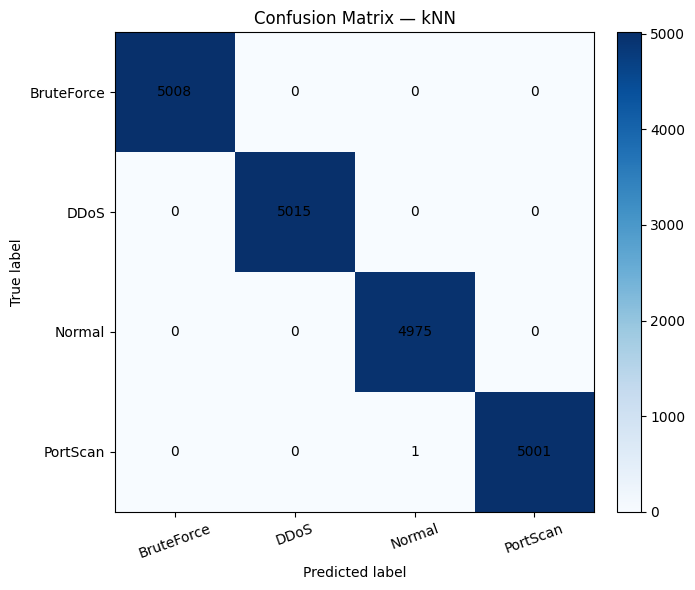

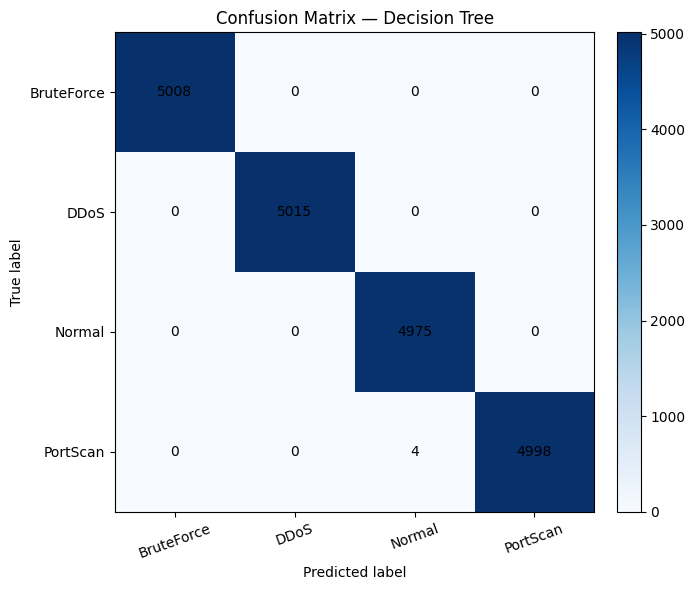

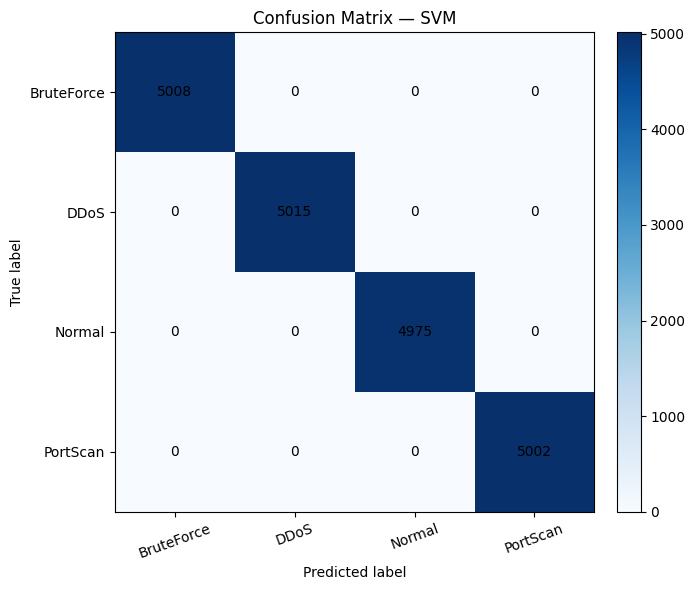

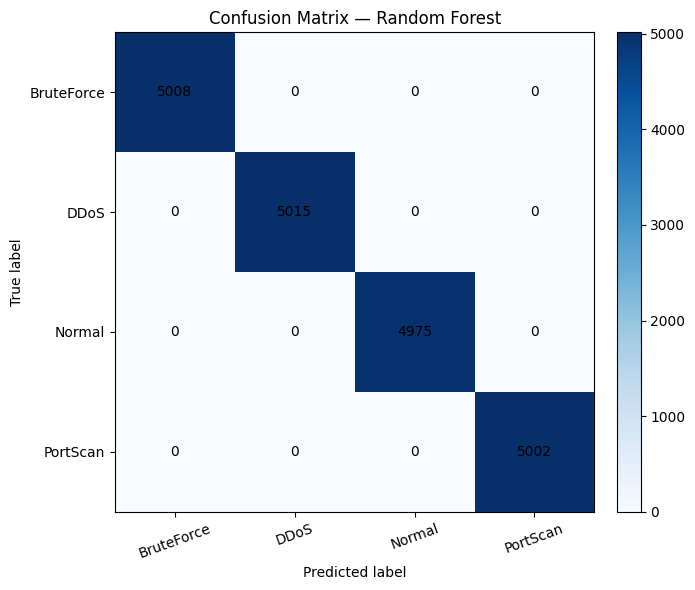

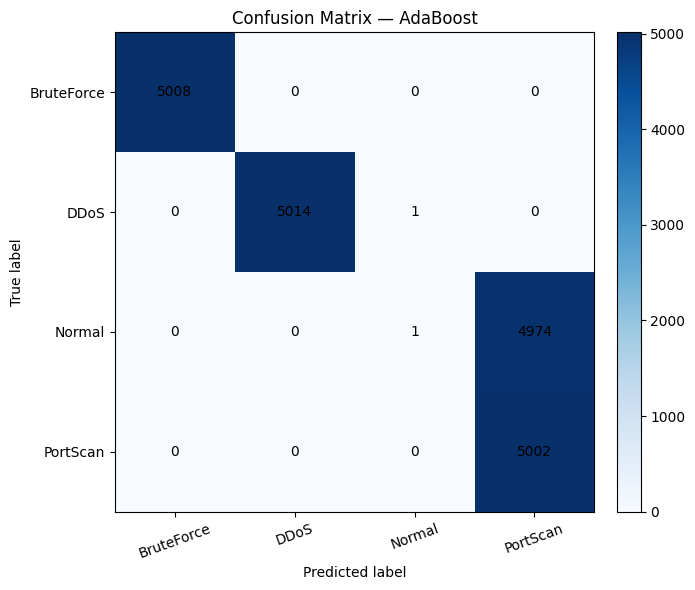

In [18]:
for name in final_models:
    cm = confusion_matrices[name]

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(class_labels)))
    ax.set_yticks(range(len(class_labels)))
    ax.set_xticklabels(class_labels, rotation=20)
    ax.set_yticklabels(class_labels)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(f"Confusion Matrix — {name}")

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center")

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

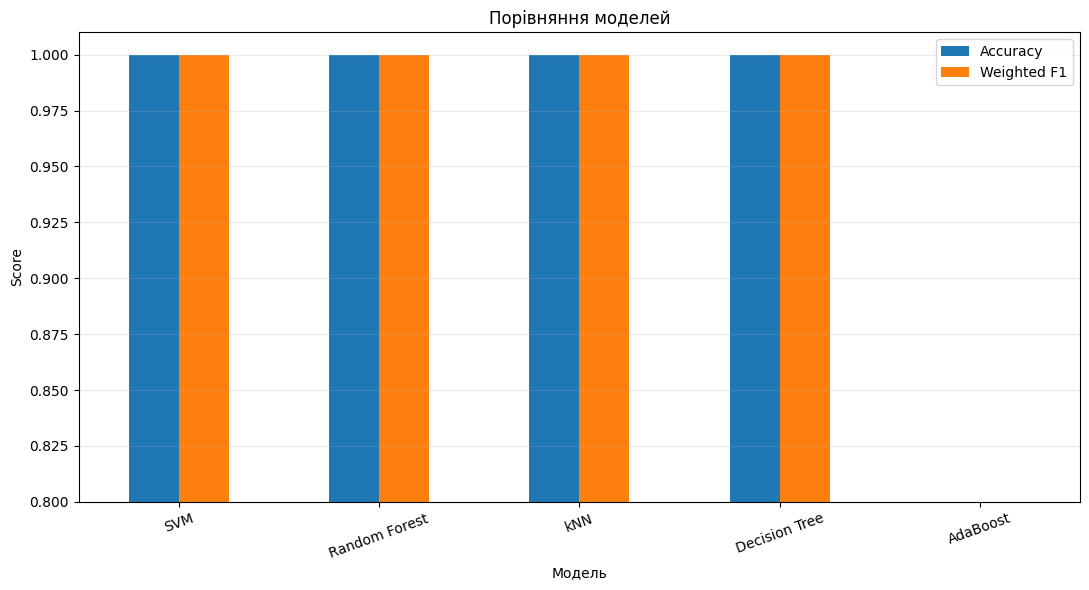

In [19]:
plot_df = results_df.set_index("Model")[["Accuracy", "Weighted F1"]]

ax = plot_df.plot(kind="bar", figsize=(11, 6), ylim=(0.8, 1.01))
ax.set_title("Порівняння моделей")
ax.set_ylabel("Score")
ax.set_xlabel("Модель")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Висновок

У роботі було розглянуто задачу класифікації мережевого трафіку за датасетом Cyber Security Attack Using Network Traffic. Цільовою змінною є attack_type, яка визначає тип атаки або нормальний трафік.

На етапі попередньої обробки було перевірено наявність пропущених значень, категоріальну ознаку protocol закодовано за допомогою One-Hot Encoding, а числові ознаки масштабовані в pipeline.

Для класифікації було протестовано п'ять алгоритмів: kNN, Decision Tree, SVM, Random Forest та AdaBoost. Був виконаний підбір оптимальних гіперпараметрів:\
-для kNN n_neighbors підібрано через GridSearchCV\
-для SVM C та gamma підібрано через GridSearchCV\
-для Decision Tree підібрано max_depth\
-для Random Forest підібрано кількість дерев\
-для AdaBoost досліджено вплив кількості weak learners

Моделі SVM та Random Forest досягають найвищої якості та мають Accuracy = 1.0 і Weighted F1 = 1.0, kNN також дає практично ідеальний результат. 

Між SVM та Random Forest доцільніше обрати Random Forest як найкращий практичний варіант саме для цього набору даних: він досягає тієї ж максимальної якості, що й RBF-SVM, добре моделює нелінійні залежності, стійкий до взаємодії ознак і не потребує такого чутливого налаштування масштабу ознак, як SVM/kNN. Крім того, Random Forest дозволяє аналізувати важливість ознак.

AdaBoost поступається іншим алгоритмам і показує близько 91% accuracy після підбору кількості базових оцінювачів. Основною причиною низької точності AdaBoost є використання простих дерева рішень, які не здатні самостійно моделювати складні межі між класами.
Це підтверджує підбір гіперпараметра для Decision Tree: при глибині дерева 2 accuracy становила лише 75.12%, тоді як при збільшенні глибини до 8 вона зросла до 99.98%. Отже, для цього датасета необхідні складніші нелінійні правила розділення класів.
Найбільші проблеми AdaBoost виникли при класифікації класу BruteForce: recall становив лише 0.64, тобто модель пропускала значну частину таких атак. Для класу Normal precision також була нижчою - 0.73, що свідчить про наявність помилкових класифікацій інших типів трафіку як нормального.
